<a href="https://colab.research.google.com/github/mksmk2012/python_projects/blob/main/Exploratory_data_analysis_for_online_store_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Online Sales Analysis Project**

This project focuses on analyzing online sales data to better understand customer behavior, product performance, and factors that influence revenue generation. The analysis is based on three related datasets containing information about orders, customers, and products.

The main goal of this project is to explore the data, identify key trends and patterns, and generate actionable insights that can support business decision-making. To achieve this goal, the datasets will be examined, cleaned, merged, and analyzed using Python data analysis libraries.

**The project includes the following stages:**
1. Data Overview
2. Cleaning
3. Analysis & Visualization
4. Conclusions & Insights

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/Mate/Final_project

countries = pd.read_csv("countries.csv")
events = pd.read_csv("events.csv")
products = pd.read_csv("products.csv")

Mounted at /content/drive
/content/drive/MyDrive/Mate/Final_project


In [ ]:
display(Markdown("## Countries dataset"))
display(countries.head())

display(Markdown("## Products dataset"))
display(products.head())

display(Markdown("## Events dataset"))
display(events.head())

## Countries dataset

,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


## Products dataset

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


## Events dataset

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79



##**1. Data Overview**

The project uses three datasets: **countries, products, events.**



---

## 1. countries
Contains information about countries, regions, and their codes.


| Column     | Description               |
| ---------- | ------------------------- |
| name       | Country name              |
| alpha-2    | Two-letter country code   |
| alpha-3    | Three-letter country code |
| region     | Region name               |
| sub-region | Sub-region name           |

---

## 2. products

Contains information about products.

| Column    | Description             |
| --------- | ----------------------- |
| id        | Product identifier      |
| item_type | Product category / type |

---

## 3. events

Contains sales transaction data.

| Column         | Description                                  |
| -------------- | -------------------------------------------- |
| Order ID       | Unique order identifier                      |
| Order Date     | Date when order was placed                   |
| Ship Date      | Date when order was shipped                  |
| Order Priority | Priority level of order                      |
| Country Code   | Country identifier (link to countries table) |
| Product ID     | Product identifier (link to products table)  |
| Sales Channel  | Channel of sale (online / offline)           |
| Units Sold     | Number of units sold                         |
| Unit Price     | Price per unit                               |
| Unit Cost      | Cost per unit                                |





In [ ]:
#Check countries df structure and missing values overview
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


In [ ]:
#Identify rows with missing values
countries_missing_rows = countries[countries.isna().any(axis=1)]

Missing values are present for Antarctica and Namibia.

For Antarctica, I impute region and sub-region with the country name to keep consistency.

For Namibia, I fill the missing alpha-2 code with the correct ISO value ("NA").

In [ ]:
countries.loc[countries["name"] == "Antarctica", "region"] = "Antarctica"
countries.loc[countries["name"] == "Antarctica", "sub-region"] = "Antarctica"
countries.loc[countries["name"] == "Namibia", "alpha-2"] = "NA"

In [ ]:
#Validate that missing values were properly handled
countries.isna().sum()

,0
name,0
alpha-2,0
alpha-3,0
region,0
sub-region,0


In [ ]:
#Check events DF structure and missing values overview
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


In [ ]:
#Identify rows with missing values
events_missing_rows = events[events.isna().any(axis=1)]
events_missing_rows

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
13,104548490,1/1/2014,1/5/2014,M,NaN,7331,Online,7076.0,255.28,159.42
26,117929494,1/24/2015,3/2/2015,H,NaN,4594,Offline,6813.0,9.33,6.92
29,118859469,6/2/2011,7/1/2011,L,NaN,8969,Offline,2013.0,152.58,97.44
43,126948583,5/24/2017,7/9/2017,C,NaN,7331,Online,5762.0,255.28,159.42
...,...,...,...,...,...,...,...,...,...,...
1213,919922006,8/27/2011,9/18/2011,L,NaN,4594,Online,4219.0,9.33,6.92
1220,922564303,3/17/2017,4/2/2017,L,NaN,7940,Offline,6134.0,668.27,502.54
1250,941061675,3/8/2017,3/20/2017,M,NaN,5988,Offline,9917.0,154.06,90.93
1296,975080668,7/23/2017,8/20/2017,C,NaN,5988,Offline,6893.0,154.06,90.93


Missing values are present in "Country Code" and "Units Sold".

For "Country Code", I fill missing values with "Unknown" because the number of missing records is relatively high, and removing them could negatively affect data integrity and downstream analysis.

For "Units Sold", I remove rows with missing values because their number is small, and keeping them would distort calculations such as totals and averages.

In [ ]:
events["Country Code"] = events["Country Code"].fillna("Unknown")
events = events.dropna(subset=["Units Sold"])

In [ ]:
#Validate that missing values were properly handled
events.isna().sum()

,0
Order ID,0
Order Date,0
Ship Date,0
Order Priority,0
Country Code,0
Product ID,0
Sales Channel,0
Units Sold,0
Unit Price,0
Unit Cost,0


In [ ]:
# Check products DF structure and missing values
products.info()

# Verify missing values
products.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


,0
id,0
item_type,0


No missing values detected in products DF


#**2. Cleaning**
Handling missing data, incorrect data, and anomalies.

In [ ]:
#Normalize all string columns
for col in countries.select_dtypes(include="object").columns:
    countries[col] = countries[col].str.strip().str.lower()
for col in products.select_dtypes(include="object").columns:
    products[col] = products[col].str.strip().str.lower()
for col in events.select_dtypes(include="object").columns:
    events[col] = events[col].str.strip().str.lower()


In [ ]:
#Convert date columns to datetime format
events["Order Date"] = pd.to_datetime(events["Order Date"])
events["Ship Date"] = pd.to_datetime(events["Ship Date"])

In [ ]:
#Standardize column names
countries.columns = countries.columns.str.lower().str.replace("-", "_")
events.columns = events.columns.str.lower().str.replace(" ", "_")


In [ ]:
#Duplicate rows summary
duplicate_summary = pd.DataFrame({
    "Dataset": ["Countries", "Products", "Events"],
    "Duplicates": [
        countries.duplicated().sum(),
        products.duplicated().sum(),
        events.duplicated().sum()
    ]
})

duplicate_summary

,Dataset,Duplicates
0,Countries,0
1,Products,0
2,Events,0


#**3. Analysis & Visualization**
Data analysis and visualization, identifying valuable insights.

In [ ]:
#Merge datasets into a single DataFrame
events_countries = pd.merge(events, countries, left_on="country_code", right_on="alpha_3", how="left")
df = pd.merge(events_countries, products, left_on="product_id", right_on="id", how="left" )
df.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,name,alpha_2,alpha_3,region,sub_region,id,item_type
0,100640618,2014-10-08,2014-10-18,m,nor,2103,online,650.0,205.70,117.11,norway,no,nor,europe,northern europe,2103,cereal
1,100983083,2016-08-11,2016-08-11,c,srb,2103,offline,1993.0,205.70,117.11,serbia,rs,srb,europe,southern europe,2103,cereal
2,101025998,2014-07-18,2014-08-11,m,unknown,7940,online,4693.0,668.27,502.54,NaN,NaN,NaN,NaN,NaN,7940,household
3,102230632,2017-05-13,2017-06-13,l,mne,2455,online,1171.0,109.28,35.84,montenegro,me,mne,europe,southern europe,2455,clothes
4,103435266,2012-08-11,2012-09-18,h,srb,1270,offline,7648.0,47.45,31.79,serbia,rs,srb,europe,southern europe,1270,beverages


In [ ]:
#Data Cleaning and Column Standardization after join
df = df.drop(columns=["id", "alpha_2", "alpha_3"])
df = df.rename(columns={"name": "country_name"})
df["country_name"] = df["country_name"].astype("string").fillna("Unknown")
df["region"] = df["region"].astype("string").fillna("Unknown")
df["sub_region"] = df["sub_region"].astype("string").fillna("Unknown")

In [ ]:
df.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country_name,region,sub_region,item_type
0,100640618,2014-10-08,2014-10-18,m,nor,2103,online,650.0,205.70,117.11,norway,europe,northern europe,cereal
1,100983083,2016-08-11,2016-08-11,c,srb,2103,offline,1993.0,205.70,117.11,serbia,europe,southern europe,cereal
2,101025998,2014-07-18,2014-08-11,m,unknown,7940,online,4693.0,668.27,502.54,Unknown,Unknown,Unknown,household
3,102230632,2017-05-13,2017-06-13,l,mne,2455,online,1171.0,109.28,35.84,montenegro,europe,southern europe,clothes
4,103435266,2012-08-11,2012-09-18,h,srb,1270,offline,7648.0,47.45,31.79,serbia,europe,southern europe,beverages


## **Exploratory Data Analysis Overview**

This section performs a comprehensive exploratory analysis of the dataset by calculating key business metrics and breaking them down across multiple dimensions, including geography, products, and sales channels.

The analysis is structured into four main parts:
- Key business metrics to understand overall scale and performance
- Revenue analysis to evaluate financial outcomes and profitability
- Product performance to identify top-performing categories
- Geographic and channel analysis to understand how sales are distributed across markets and channels

The goal of this section is to provide a high-level understanding of business performance and identify the main drivers of revenue, orders, and product demand.

In [ ]:
#Key Metrics Overview
df["revenue"] = df["units_sold"]*df["unit_price"]
df["cost"] = df["units_sold"]*df["unit_cost"]
df["profit"] = df["revenue"]-df["cost"]
total_orders = df["order_id"].nunique()
countries_cnt = df["country_name"].nunique()
products_cnt = df["item_type"].nunique()
total_cost = df["cost"].sum()
total_profit = df["profit"].sum()

print(f"Total Orders      : {total_orders:,}")
print(f"Countries Covered : {countries_cnt}")
print(f"Product Categories: {products_cnt}")
print(f"Total Cost        : ${total_cost:,.2f}")
print(f"Total Profit      : ${total_profit:,.2f}")

Total Orders      : 1,328
Countries Covered : 46
Product Categories: 12
Total Cost        : $1,200,694,949.21
Total Profit      : $501,434,459.00


In [ ]:
#Revenue Analysis
total_revenue = df["revenue"].sum()
revenue_by_category = df.groupby("item_type")["revenue"].sum().sort_values(ascending=False).reset_index()
order_revenue = df.groupby("order_id")["revenue"].sum()
avg_order_value = order_revenue.mean()

Total Revenue      : $1,702,129,408.21
Average Order Value: $1,281,723.95

Top 5 Product Categories by Revenue:
      item_type      revenue
office supplies 402213995.61
      household 294205199.23
      cosmetics 233154825.20
           meat 223762018.20
      baby food 143647587.68


In [ ]:
#Product Performance
total_units_sold = df["units_sold"].sum()
avg_units_per_order = total_units_sold/total_orders
top_products = df.groupby("item_type")["units_sold"].sum().sort_values(ascending=False)

In [ ]:
#Geographic Analysis

top_country_summary = df[df["country_name"] != "Unknown"].groupby("country_name").agg(revenue = ("revenue", "sum"), orders = ("order_id", "nunique"), units_sells = ("units_sold", "sum")).reset_index().sort_values(by="revenue", ascending=False)
region_summary = df[df["region"] != "Unknown"].groupby("region").agg(revenue = ("revenue", "sum"), orders = ("order_id", "nunique"), units_sells = ("units_sold", "sum")).reset_index()
top_country_by_revenue = top_country_summary.head(10)


# Revenue share
revenue_share_country = top_country_summary["revenue"] / top_country_summary["revenue"] .sum() * 100
revenue_share_region = region_summary["revenue"] / region_summary["revenue"].sum() * 100

# Orders share
orders_share_country = top_country_summary["orders"] / top_country_summary["orders"].sum() * 100
orders_share_region = region_summary["orders"] / region_summary["orders"].sum() * 100

# Units share
units_share_country = top_country_summary["units_sells"] / top_country_summary["units_sells"].sum() * 100
units_share_region = region_summary["units_sells"] / region_summary["units_sells"].sum() * 100

In [ ]:
#Channel Analysis
channel_summary = df.groupby("sales_channel").agg(revenue = ("revenue", "sum"), orders = ("order_id", "nunique"), sales = ("units_sold", "sum")).reset_index()

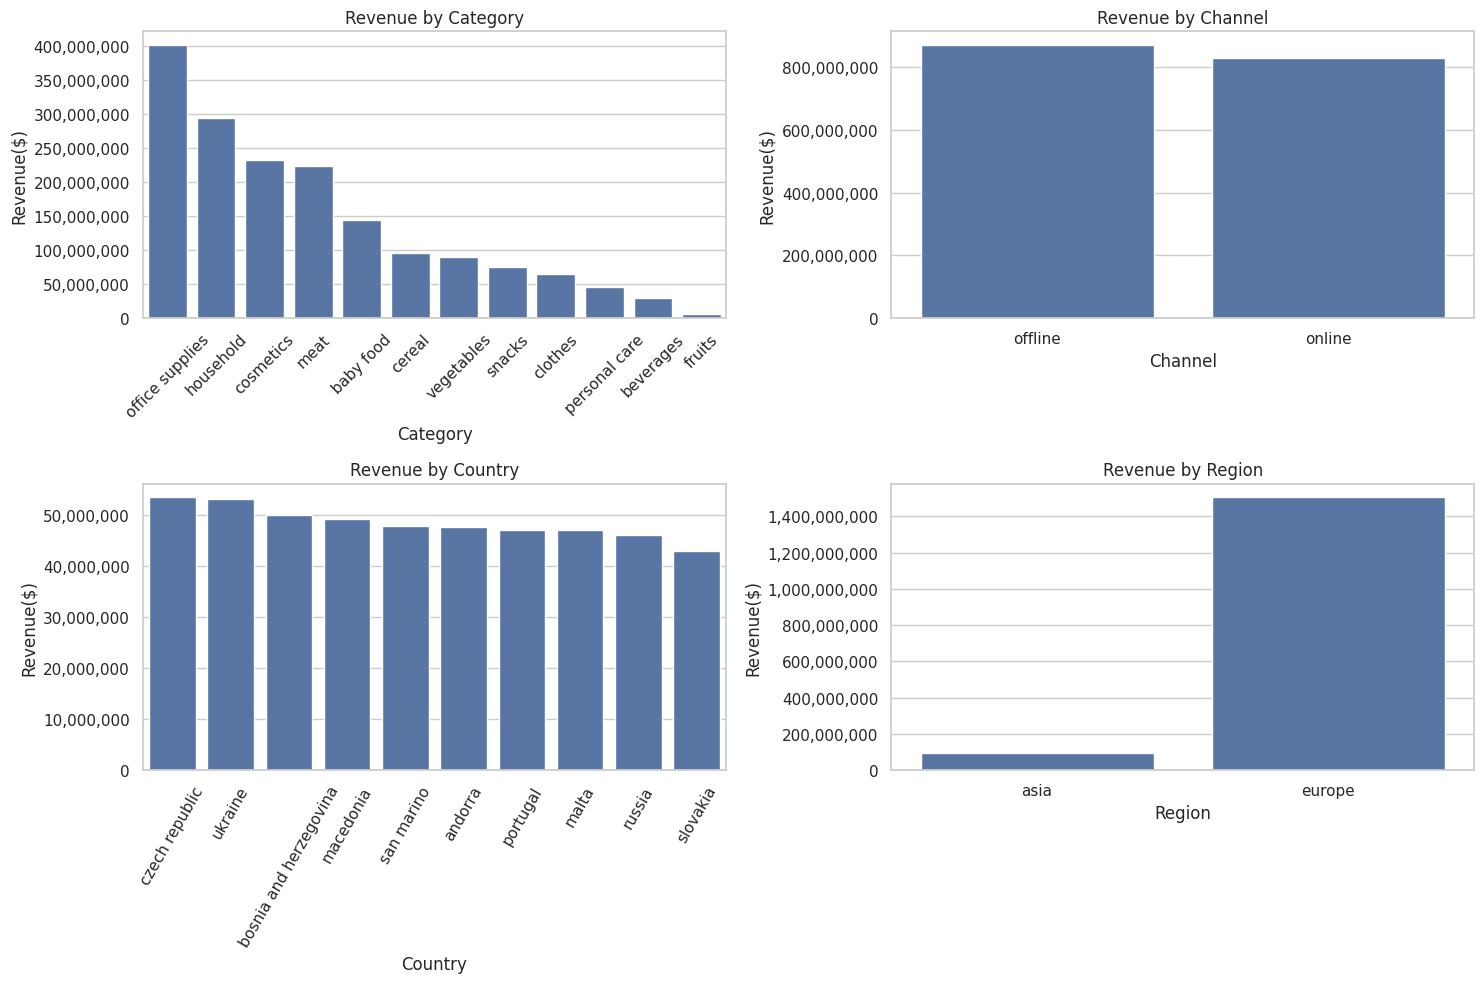

In [ ]:
#Visualize revenue performance across key business dimensions: product categories, sales channels, countries, and regions.

fig, ax = plt.subplots(2, 2, figsize=(15,10))
sns.barplot(data=revenue_by_category, x="item_type", y="revenue", ax=ax[0,0])
ax[0,0].set_title("Revenue by Category")
ax[0,0].set_xlabel("Category")
ax[0,0].set_ylabel("Revenue($)")
ax[0,0].tick_params(axis="x", rotation=45)
ax[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=top_country_by_revenue, x="country_name", y="revenue", ax=ax[1,0])
ax[1,0].set_title("Revenue by Country")
ax[1,0].set_xlabel("Country")
ax[1,0].set_ylabel("Revenue($)")
ax[1,0].tick_params(axis="x", rotation=60)
ax[1,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=region_summary, x="region", y="revenue", ax=ax[1,1])
ax[1,1].set_title("Revenue by Region")
ax[1,1].set_xlabel("Region")
ax[1,1].set_ylabel("Revenue($)")
ax[1,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=channel_summary, x="sales_channel", y="revenue", ax=ax[0,1])
ax[0,1].set_title("Revenue by Channel")
ax[0,1].set_xlabel("Channel")
ax[0,1].set_ylabel("Revenue($)")
ax[0,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))
plt.tight_layout()
plt.show()

### Key Findings

- **Office Supplies** generated the highest revenue among all product categories, making it the strongest contributor to overall sales.
- Revenue generated through **online and offline channels is relatively balanced**, indicating that both sales channels play an equally important role in the business.
- **Ukraine and the Czech Republic** are the leading countries in terms of revenue contribution.
- **Europe dominates by a significant margin**, accounting for the largest share of total revenue.

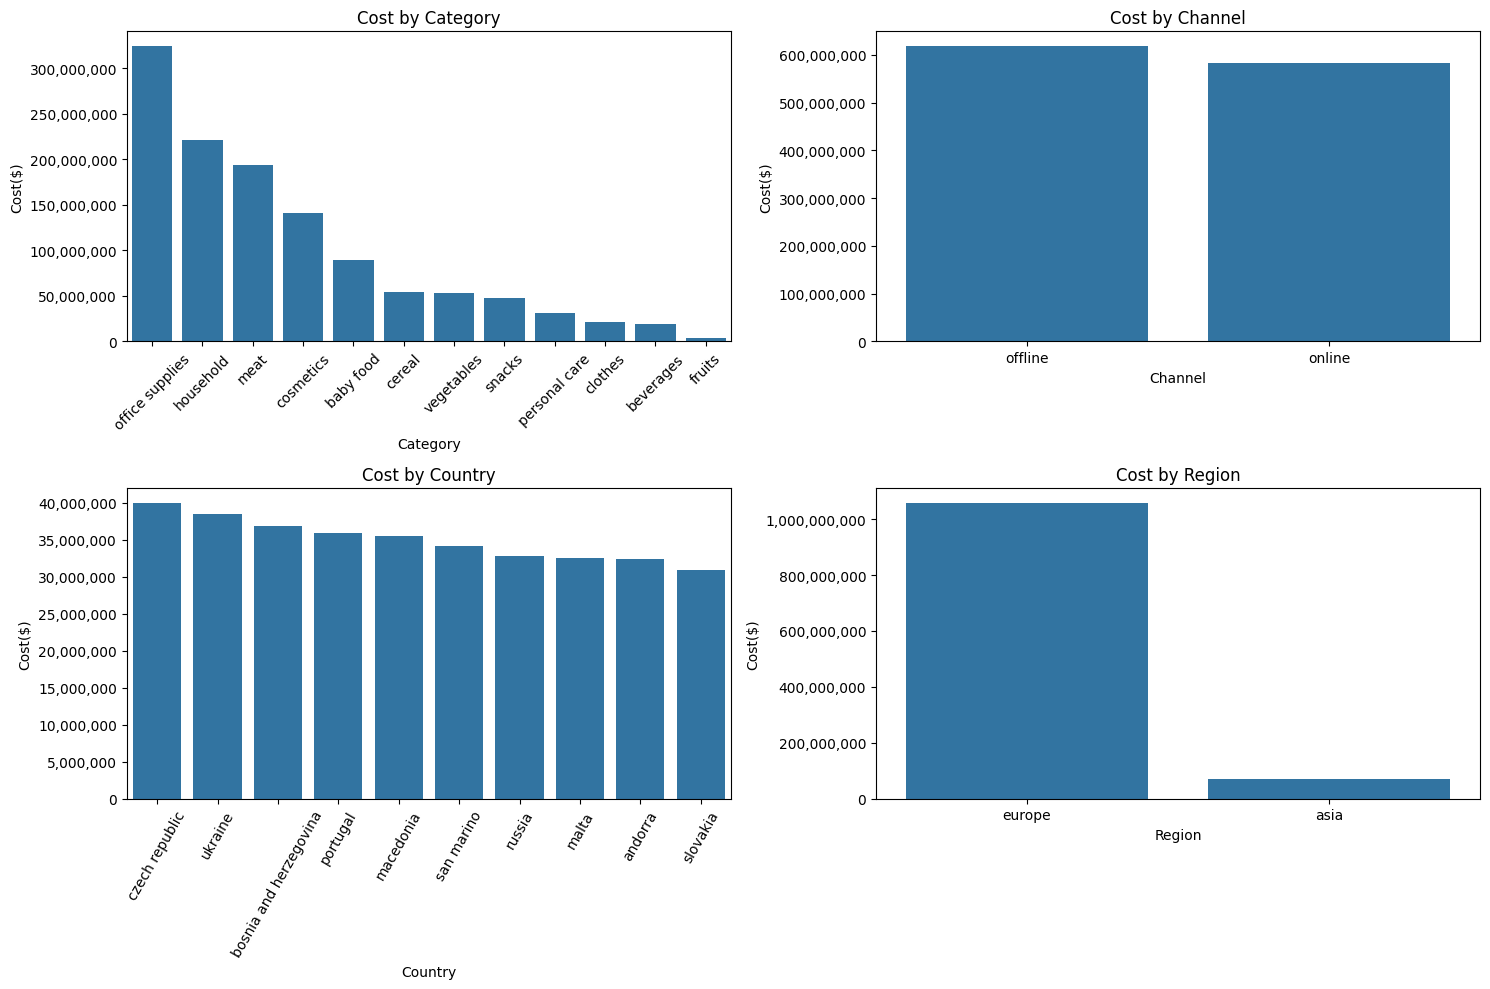

In [ ]:
#Analyze and visualize cost distribution across product categories,
#sales channels, countries, and regions.

cost_by_category = df.groupby("item_type")["cost"].sum().sort_values(ascending=False).reset_index()
cost_by_country = df[df["country_name"] != "Unknown"].groupby("country_name")["cost"].sum().sort_values(ascending=False).reset_index().head(10)
cost_by_region = df[df["region"] != "Unknown"].groupby("region")["cost"].sum().sort_values(ascending=False).reset_index()
cost_by_channel = df.groupby("sales_channel")["cost"].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(2, 2, figsize=(15,10))
sns.barplot(data=cost_by_category, x="item_type", y="cost", ax=ax[0,0])
ax[0,0].set_title("Cost by Category")
ax[0,0].set_xlabel("Category")
ax[0,0].set_ylabel("Cost($)")
ax[0,0].tick_params(axis="x", rotation=45)
ax[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=cost_by_country, x="country_name", y="cost", ax=ax[1,0])
ax[1,0].set_title("Cost by Country")
ax[1,0].set_xlabel("Country")
ax[1,0].set_ylabel("Cost($)")
ax[1,0].tick_params(axis="x", rotation=60)
ax[1,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=cost_by_region, x="region", y="cost", ax=ax[1,1])
ax[1,1].set_title("Cost by Region")
ax[1,1].set_xlabel("Region")
ax[1,1].set_ylabel("Cost($)")
ax[1,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=cost_by_channel, x="sales_channel", y="cost", ax=ax[0,1])
ax[0,1].set_title("Cost by Channel")
ax[0,1].set_xlabel("Channel")
ax[0,1].set_ylabel("Cost($)")
ax[0,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

plt.tight_layout()
plt.show()

### Key Findings

- **Office Supplies** generated the highest total cost, significantly exceeding all other product categories.
- Cost distribution between **online and offline channels** is relatively balanced, with offline sales accounting for a slightly larger share.
- **The Czech Republic and Ukraine** are among the countries with the highest total costs.
- **Europe** dominates in terms of total cost, indicating that the majority of business activity is concentrated in the European market.

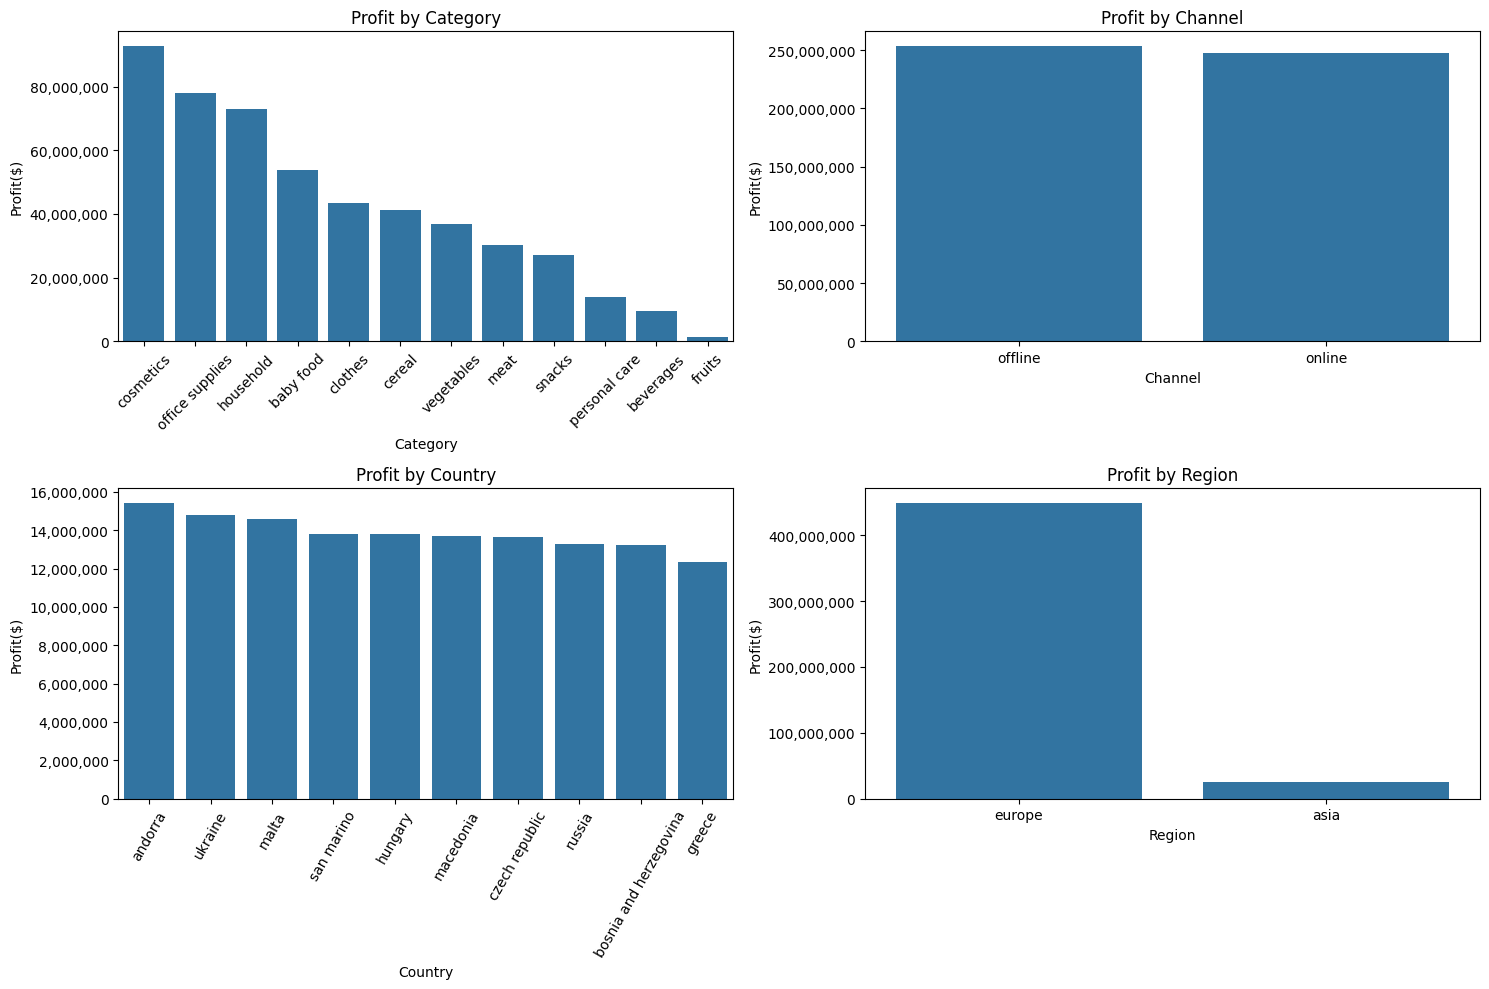

In [ ]:
#Aggregate profit data and compare profitability across key business dimensions
#to identify the most profitable products, markets, and sales channels.

profit_by_category = df.groupby("item_type")["profit"].sum().sort_values(ascending=False).reset_index()
profit_by_country = df[df["country_name"] != "Unknown"].groupby("country_name")["profit"].sum().sort_values(ascending=False).reset_index().head(10)
profit_by_region = df[df["region"] != "Unknown"].groupby("region")["profit"].sum().sort_values(ascending=False).reset_index()
profit_by_channel = df.groupby("sales_channel")["profit"].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(2, 2, figsize=(15,10))
sns.barplot(data=profit_by_category, x="item_type", y="profit", ax=ax[0,0])
ax[0,0].set_title("Profit by Category")
ax[0,0].set_xlabel("Category")
ax[0,0].set_ylabel("Profit($)")
ax[0,0].tick_params(axis="x", rotation=45)
ax[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=profit_by_country, x="country_name", y="profit", ax=ax[1,0])
ax[1,0].set_title("Profit by Country")
ax[1,0].set_xlabel("Country")
ax[1,0].set_ylabel("Profit($)")
ax[1,0].tick_params(axis="x", rotation=60)
ax[1,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=profit_by_region, x="region", y="profit", ax=ax[1,1])
ax[1,1].set_title("Profit by Region")
ax[1,1].set_xlabel("Region")
ax[1,1].set_ylabel("Profit($)")
ax[1,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=profit_by_channel, x="sales_channel", y="profit", ax=ax[0,1])
ax[0,1].set_title("Profit by Channel")
ax[0,1].set_xlabel("Channel")
ax[0,1].set_ylabel("Profit($)")
ax[0,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

plt.tight_layout()
plt.show()

### Key Findings

- **Cosmetics** is the most profitable product category, followed by **Office Supplies** and **Household** products.
- Profit generated through **online and offline channels is nearly identical**, indicating a balanced contribution from both sales channels.
- The highest profits were generated in **Andorra, Ukraine, and Malta**, although the differences among the top countries are relatively small.
- **Europe overwhelmingly dominates profitability**, while Asia contributes only a small fraction of total profit.
- Profitability appears to be highly concentrated in the European market, suggesting that the company relies heavily on this region for financial performance.

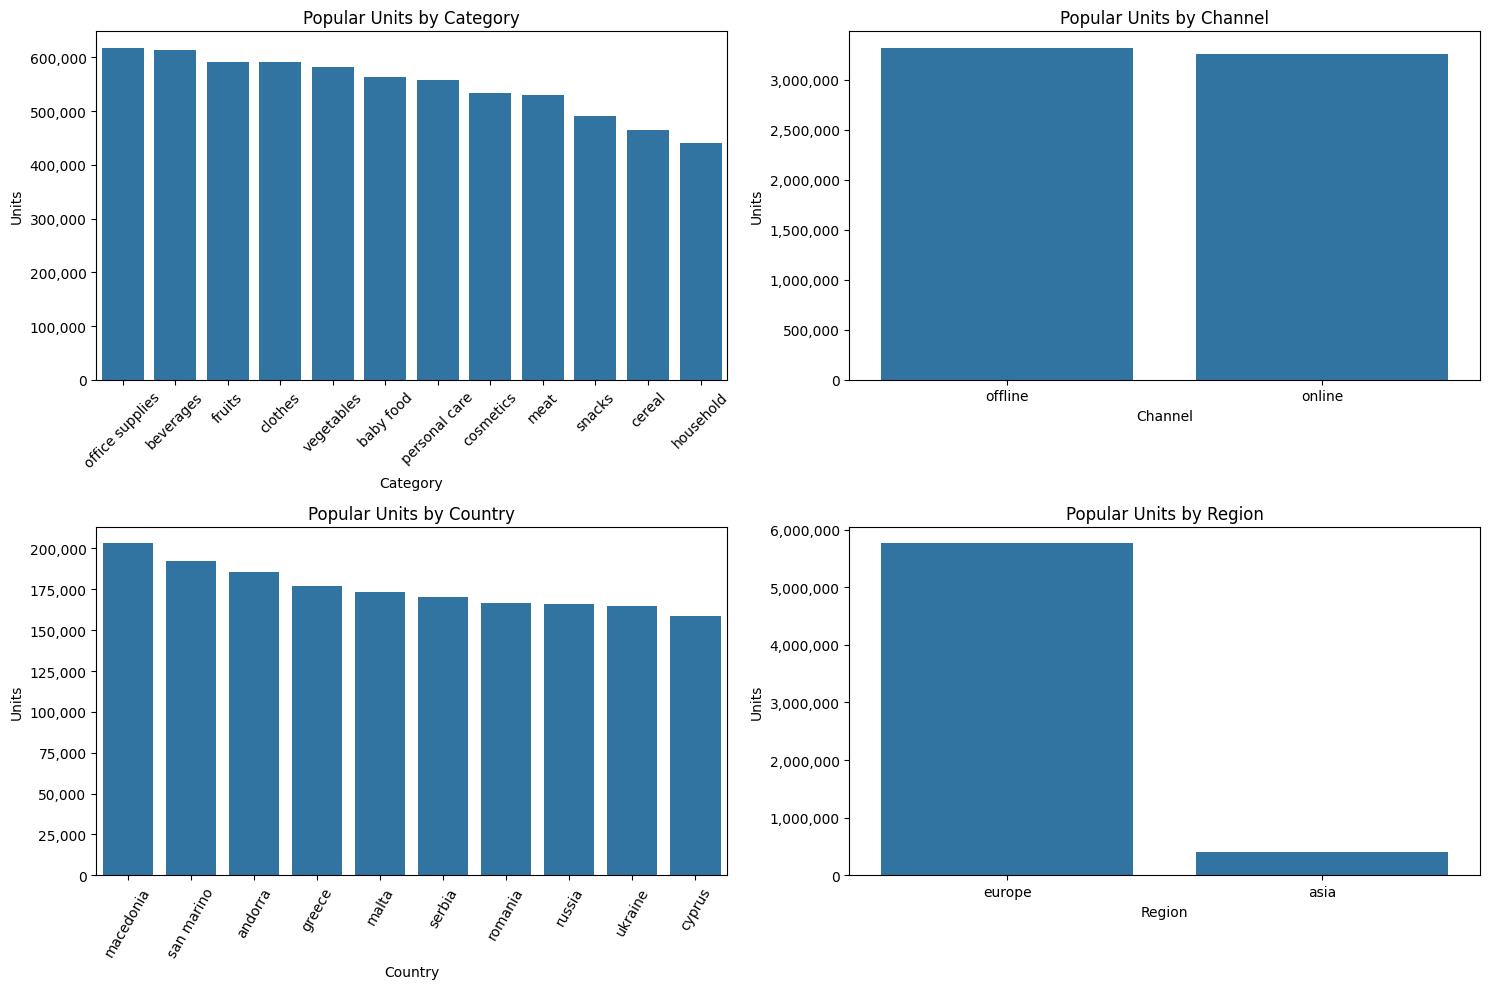

In [ ]:
#Analyze and visualize product demand based on the total number of units sold
#across product categories, sales channels, countries, and regions.
popular_units_by_category = df.groupby("item_type")["units_sold"].sum().sort_values(ascending=False).reset_index()
popular_units_by_country = df[df["country_name"] != "Unknown"].groupby("country_name")["units_sold"].sum().sort_values(ascending=False).reset_index().head(10)
popular_units_by_region = df[df["region"] != "Unknown"].groupby("region")["units_sold"].sum().sort_values(ascending=False).reset_index()
popular_units_by_channel = df.groupby("sales_channel")["units_sold"].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(2, 2, figsize=(15,10))
sns.barplot(data=popular_units_by_category, x="item_type", y="units_sold", ax=ax[0,0])
ax[0,0].set_title("Popular Units by Category")
ax[0,0].set_xlabel("Category")
ax[0,0].set_ylabel("Units")
ax[0,0].tick_params(axis="x", rotation=45)
ax[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=popular_units_by_country, x="country_name", y="units_sold", ax=ax[1,0])
ax[1,0].set_title("Popular Units by Country")
ax[1,0].set_xlabel("Country")
ax[1,0].set_ylabel("Units")
ax[1,0].tick_params(axis="x", rotation=60)
ax[1,0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=popular_units_by_region, x="region", y="units_sold", ax=ax[1,1])
ax[1,1].set_title("Popular Units by Region")
ax[1,1].set_xlabel("Region")
ax[1,1].set_ylabel("Units")
ax[1,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

sns.barplot(data=popular_units_by_channel, x="sales_channel", y="units_sold", ax=ax[0,1])
ax[0,1].set_title("Popular Units by Channel")
ax[0,1].set_xlabel("Channel")
ax[0,1].set_ylabel("Units")
ax[0,1].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))

plt.tight_layout()
plt.show()

### Key Findings

- **Office Supplies** is the most popular product category by units sold, followed closely by **Beverages** and **Fruits**.
- The number of units sold is distributed relatively evenly across product categories, with no single category showing overwhelming dominance.
- **Online and offline channels generate a similar sales volume**, indicating balanced customer demand across both channels.
- **Macedonia, San Marino, and Andorra** recorded the highest sales volumes among countries.
- **Europe accounts for the vast majority of units sold**, significantly outperforming Asia and highlighting the company's strong presence in the European market.

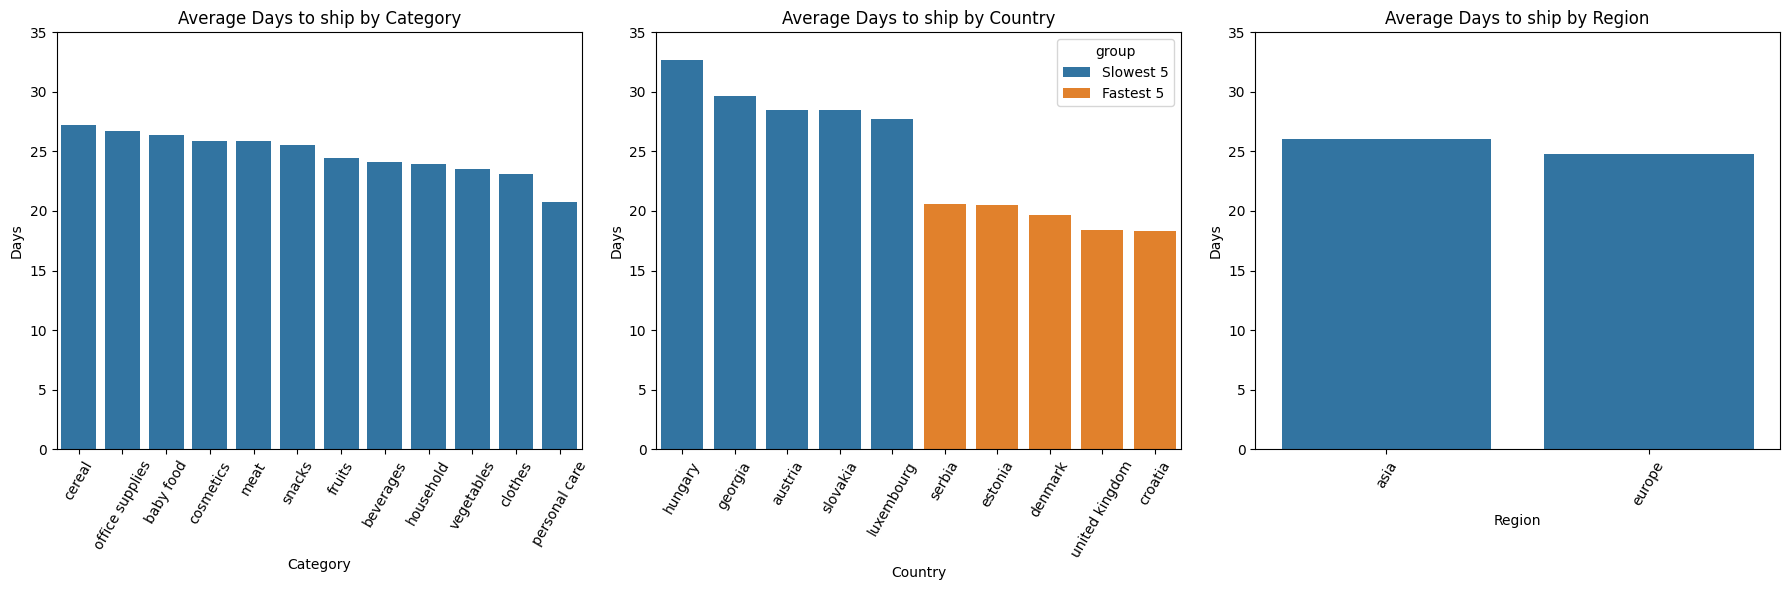

In [ ]:
#Calculate the average time between order placement and shipment across product categories, countries, and regions.

df["days_to_ship"] = (df["ship_date"] - df["order_date"]).dt.days
category_days_to_ship = df.groupby("item_type")["days_to_ship"].mean().sort_values(ascending=False).reset_index()
country_days_to_ship = df.groupby("country_name")["days_to_ship"].mean().sort_values(ascending=False).reset_index()
slowest5_countries = country_days_to_ship.head(5).copy()
fastest5_countries = country_days_to_ship.tail(5).copy()
slowest5_countries["group"] = "Slowest 5"
fastest5_countries["group"] = "Fastest 5"
country_plot = pd.concat([slowest5_countries, fastest5_countries]).reset_index(drop=True)
region_days_to_ship = df[df["region"] != "Unknown"].groupby("region")["days_to_ship"].mean().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(18,6))
sns.barplot(data=category_days_to_ship, x="item_type", y="days_to_ship", ax=ax[0])
ax[0].set_title("Average Days to ship by Category")
ax[0].set_xlabel("Category")
ax[0].set_ylabel("Days")
ax[0].tick_params(axis="x", rotation=60)
ax[0].set_ylim(0, 35)

sns.barplot(data=country_plot, x="country_name", y="days_to_ship", hue="group", ax=ax[1])
ax[1].set_title("Average Days to ship by Country")
ax[1].set_xlabel("Country")
ax[1].set_ylabel("Days")
ax[1].tick_params(axis="x", rotation=60)
ax[1].set_ylim(0, 35)

sns.barplot(data=region_days_to_ship, x="region", y="days_to_ship", ax=ax[2])
ax[2].set_title("Average Days to ship by Region")
ax[2].set_xlabel("Region")
ax[2].set_ylabel("Days")
ax[2].tick_params(axis="x", rotation=60)
ax[2].set_ylim(0, 35)

plt.tight_layout()
plt.show()



# Shipping Time Insights
- Categories differ only slightly (≈21–27 days). Slowest: **Cereal**, fastest: **Personal Care**.  
- Countries show the biggest variation (≈27–32 days). Slowest: **Hungary**, fastest: **Croatia**.  
- Regions are almost identical: **Asia ~26 days**, **Europe ~25 days**.  
- Main driver of delays is **country-level logistics**, not product type or region.


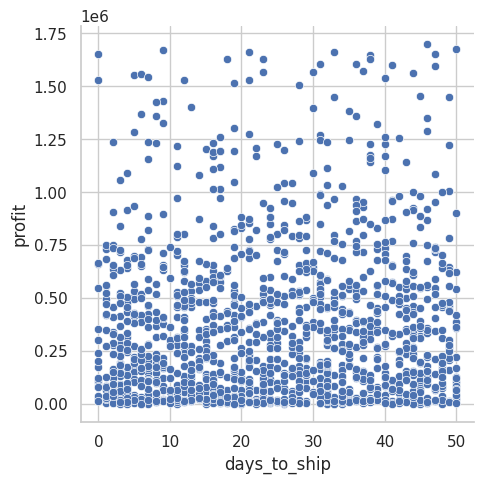

In [ ]:
# Checking the relationship between shipping time and profit using a scatter plot
sns.relplot(data=df, x="days_to_ship", y="profit", kind="scatter")

The scatter plot **shows no clear relationship** between shipping time (days_to_ship) and average profit. The data points are widely dispersed across the chart, indicating a weak or negligible correlation between these variables. Higher shipping times do not consistently result in either higher or lower profits. Therefore, shipping duration alone does not appear to be a significant factor influencing profitability in this dataset.

In [ ]:
df.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country_name,region,sub_region,item_type,revenue,cost,profit,days_to_ship
0,100640618,2014-10-08,2014-10-18,m,nor,2103,online,650.0,205.70,117.11,norway,europe,northern europe,cereal,133705.00,76121.50,57583.50,10
1,100983083,2016-08-11,2016-08-11,c,srb,2103,offline,1993.0,205.70,117.11,serbia,europe,southern europe,cereal,409960.10,233400.23,176559.87,0
2,101025998,2014-07-18,2014-08-11,m,unknown,7940,online,4693.0,668.27,502.54,Unknown,Unknown,Unknown,household,3136191.11,2358420.22,777770.89,24
3,102230632,2017-05-13,2017-06-13,l,mne,2455,online,1171.0,109.28,35.84,montenegro,europe,southern europe,clothes,127966.88,41968.64,85998.24,31
4,103435266,2012-08-11,2012-09-18,h,srb,1270,offline,7648.0,47.45,31.79,serbia,europe,southern europe,beverages,362897.60,243129.92,119767.68,38


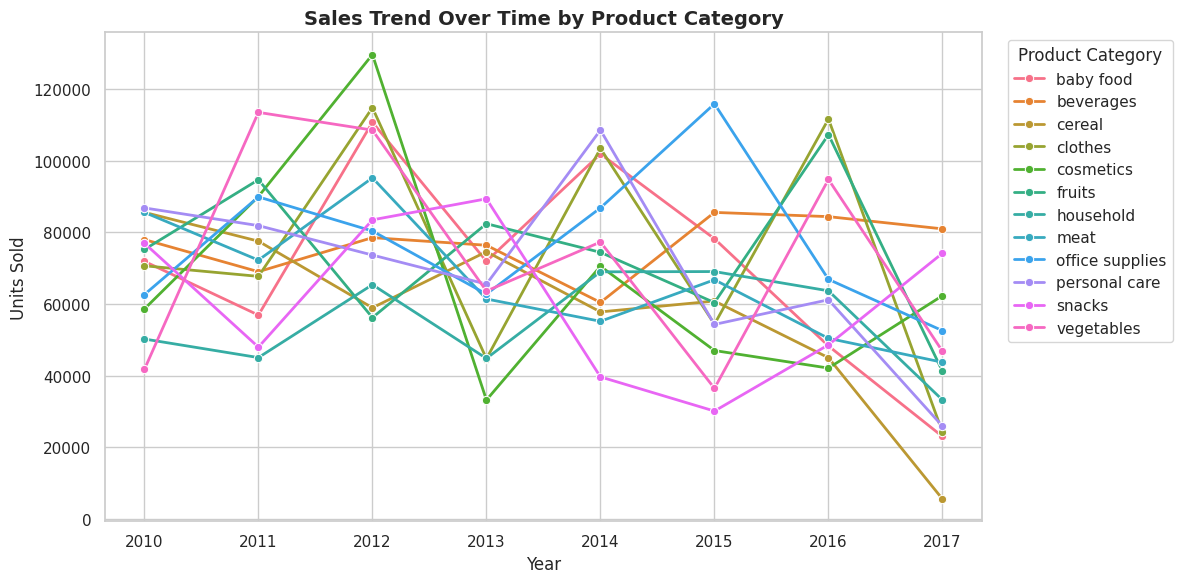

In [ ]:
#Sales dynamics over time by product categories
df["order_year"] = df["order_date"].dt.year
sales_by_year = df.groupby(["order_year", "item_type"])["units_sold"].sum().reset_index()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=sales_by_year,
    x="order_year",
    y="units_sold",
    hue="item_type",
    marker="o",
    linewidth=2
)

plt.title("Sales Trend Over Time by Product Category", fontsize=14, weight="bold")
plt.xlabel("Year")
plt.ylabel("Units Sold")

plt.legend(title="Product Category", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()


# Sales Trend by Category
- Most categories show **cyclical peaks** around **2012** and **2016**.  
- No single category dominates consistently.

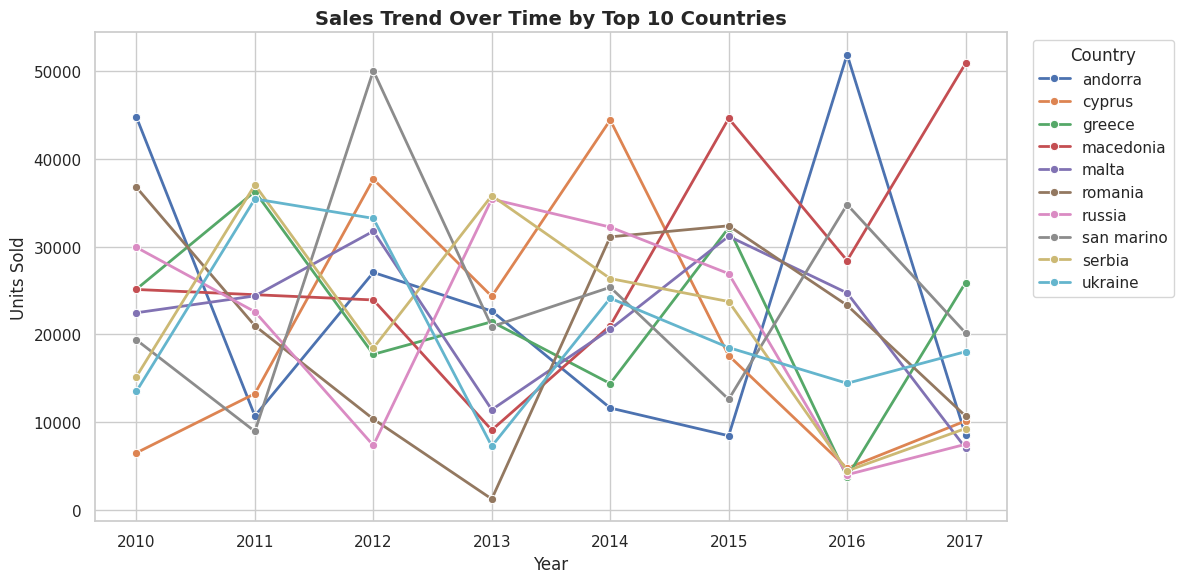

In [ ]:
#Sales dynamics over time by countries
top_countries = df[df["country_name"] != "Unknown"].groupby("country_name")["units_sold"].sum().sort_values(ascending=False).head(10).index
sales_by_year_country = df[df["country_name"].isin(top_countries)].groupby(["order_year", "country_name"])["units_sold"].sum().reset_index()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=sales_by_year_country,
    x="order_year",
    y="units_sold",
    hue="country_name",
    marker="o",
    linewidth=2
)

plt.title("Sales Trend Over Time by Top 10 Countries", fontsize=14, weight="bold")
plt.xlabel("Year")
plt.ylabel("Units Sold")

plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()


# Sales Trend Over Time by Top 10 Countries
- Sales performance varied considerably across the top 10 countries.
- Most countries experienced substantial fluctuations in annual sales volumes, indicating changing market demand over time.


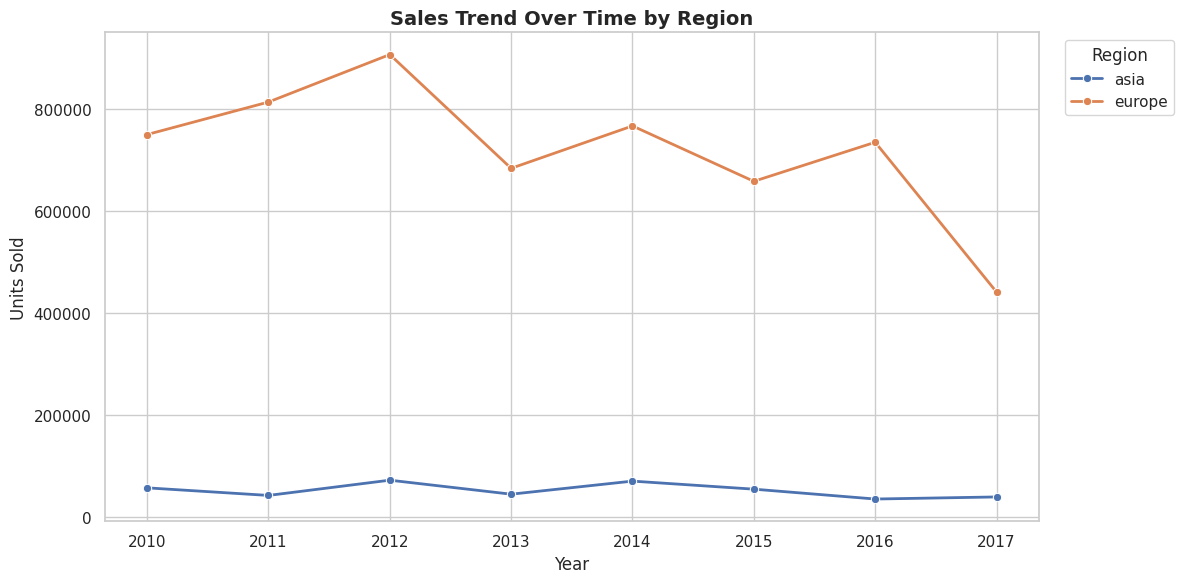

In [ ]:
#Sales dynamics over time by region
sales_by_year_region = df[df["region"] != "Unknown"].groupby(["order_year", "region"])["units_sold"].sum().reset_index()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=sales_by_year_region,
    x="order_year",
    y="units_sold",
    hue="region",
    marker="o",
    linewidth=2
)

plt.title("Sales Trend Over Time by Region", fontsize=14, weight="bold")
plt.xlabel("Year")
plt.ylabel("Units Sold")

plt.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Sales Trend Over Time by Region
- Europe consistently generated significantly higher sales volumes than Asia throughout the analyzed period.
- European sales reached their highest level in 2012, followed by fluctuations and a noticeable decline in 2017.
- Sales in Asia remained relatively stable, with only minor year-to-year changes.
- Overall, Europe was the dominant region in terms of units sold.

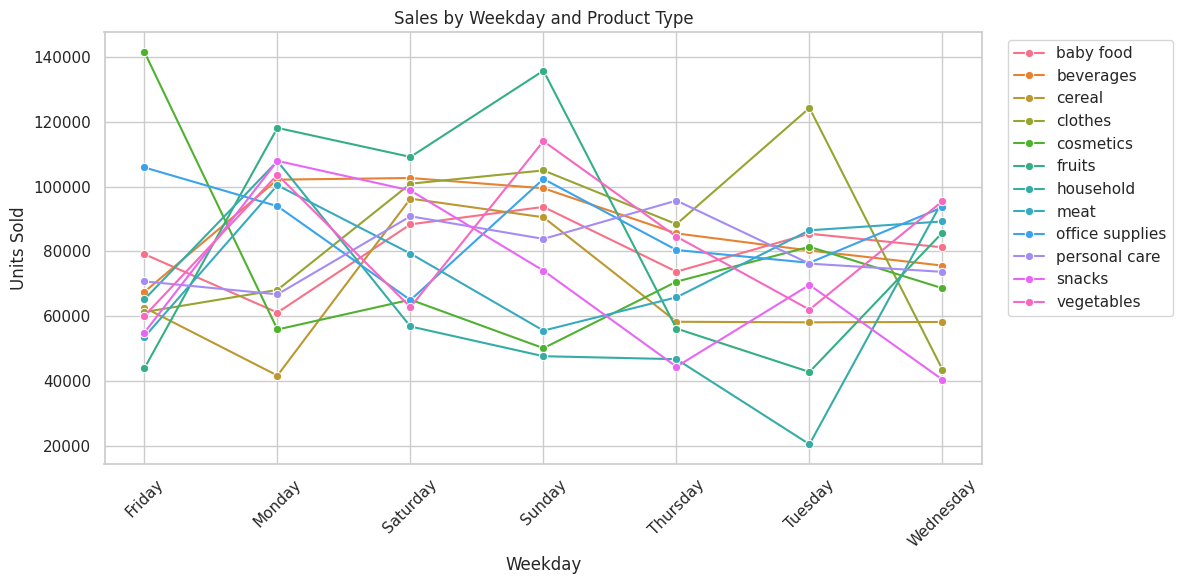

In [ ]:
#Analyze sales by weekday and product type
df["weekday"] = df["order_date"].dt.day_name()
seles_by_day = df.groupby(["item_type", "weekday"])["units_sold"].sum().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=seles_by_day,
    x="weekday",
    y="units_sold",
    hue="item_type",
    marker="o"
)

plt.title("Sales by Weekday and Product Type")
plt.xlabel("Weekday")
plt.ylabel("Units Sold")

plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()



#Sales Trend Over Time by Category

- Sales volume varies across weekdays for most product categories, indicating that customer demand is not evenly distributed throughout the week.
- Some categories, such as **Fruits** and **Cereal**, show noticeable spikes on specific days, suggesting potential weekly purchasing patterns.
- Other categories maintain relatively stable sales levels throughout the week, indicating consistent demand regardless of the day.
- No clear universal peak day is observed across all product categories, as different products reach their highest sales volumes on different weekdays.

#**4. Conclusions & Insights**

###**Overall Business Conclusions**
The exploratory analysis reveals that the company’s business performance is heavily concentrated in the European market. Europe consistently leads in revenue, profit, and sales volume, making it the primary driver of overall business success. While this demonstrates a strong market position, it also suggests a potential risk associated with geographic dependence on a single region.

Office Supplies is the company's strongest category in terms of revenue generation and units sold, indicating high customer demand and a significant contribution to overall sales activity. However, Cosmetics emerged as the most profitable category, suggesting higher profit margins and greater profitability per sale. This highlights an opportunity to further expand high-margin product segments while maintaining the strong sales performance of Office Supplies.

Sales performance is well balanced between online and offline channels. Revenue, profit, and sales volumes are distributed relatively evenly across both channels, indicating an effective multi-channel sales strategy and reducing reliance on a single distribution method.

The shipping time analysis shows that differences in order processing time are relatively small across product categories and regions, while larger variations exist between individual countries. This suggests that local logistics and operational factors have a greater impact on fulfillment efficiency than product characteristics or regional location. Furthermore, no meaningful relationship was found between shipping time and profitability, indicating that longer fulfillment times do not necessarily reduce financial performance.

Trend analysis demonstrates that sales volumes fluctuate over time across categories and countries, reflecting changing market conditions and customer demand. Europe remained the dominant region throughout the analyzed period, while Asia maintained a smaller but relatively stable sales volume. Several product categories experienced cyclical peaks, suggesting recurring demand patterns that may warrant further investigation.

Overall, the company demonstrates strong financial performance, diversified sales channels, stable operational efficiency, and a dominant position in the European market. Future growth opportunities may include expanding high-margin product categories, strengthening underrepresented geographic markets, and further diversifying revenue sources beyond Europe.